# PolicyLens — Data Exploration, Safe Cleaning & Annotation Preparation
**Notebook:** `01_data_exploration_cleaning.ipynb`  
**Author:** Senior Data Scientist, PolicyLens Research Team  
**Phase:** Phase 1 (Data Foundation) → Phase 2 (Annotation Preparation)  
**Dataset:** Open Government Consultation Data 2017–18 Get Involved Questionnaire  

---

### Notebook Objectives & Roadmap
1. **Load Data:** Inspect dataset locations in prioritized order, handle `Windows-1252` encoding, and parse multi-row bilingual headers.
2. **Understand the Dataset:** Conduct thorough Exploratory Data Analysis (EDA) on missing values, exact and near-duplicates, stakeholder distributions, language splits, and text length metrics. Inspect 30 random real comments.
3. **Clean Safely:** Apply lossless cleaning — strip whitespace, standardize nulls, preserve original verbatim text (accents, punctuation, Hinglish/slang, capitalization), without stemming, stopword removal, or automated translation.
4. **Create Canonical Comments Dataset:** Unpivot wide survey answers into the canonical schema:
   `[comment_id, comment, source_document, source_url, section_page, stakeholder, topic, stance, concern, demand, language, source_question]`
5. **Prepare Annotation Files:** Sample 200 diverse, substantive real comments for initial human annotation with blank target fields.
6. **Save Outputs:** Export profile reports, previews, cleaned datasets, annotation batches, and charts.
7. **Validate:** Enforce strict assertions on schema integrity, ID stability, and text preservation.

In [1]:
# Setup, Imports, and Path Resolution
import os
import sys
import re
import json
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import chardet

# Set styling for publication-quality figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Fixed random seed for 100% reproducible sampling & inspection
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Resolve project root dynamically (works from /notebooks or project root)
current_dir = Path.cwd().resolve()
if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = Path("/Users/pankaj/Desktop/Project/major project/Code").resolve()

# Ensure backend imports work
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Output directories
DATA_DIR = PROJECT_ROOT / "data"
INTERIM_DIR = DATA_DIR / "interim"
PROCESSED_DIR = DATA_DIR / "processed"
ANNOTATED_DIR = DATA_DIR / "annotated"
RESULTS_EXPLORATION_DIR = PROJECT_ROOT / "results" / "data_exploration"
DOCS_ANNOTATION_DIR = PROJECT_ROOT / "docs" / "annotation"

for d in [INTERIM_DIR, PROCESSED_DIR, ANNOTATED_DIR, RESULTS_EXPLORATION_DIR, DOCS_ANNOTATION_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"✅ Project root resolved to: {PROJECT_ROOT}")
print(f"✅ Results chart directory: {RESULTS_EXPLORATION_DIR}")

✅ Project root resolved to: /Users/pankaj/Desktop/Project/major project/Code
✅ Results chart directory: /Users/pankaj/Desktop/Project/major project/Code/results/data_exploration


---
## Section 1: Load Data & Inspect Sources

We check dataset locations in the exact order requested:
1. `data/processed/og2017_18_questionnaire_comments_v1.0.0.csv`
2. `data/processed/og2017_18_questionnaire_curated_v1.0.0.csv`
3. `data/raw/` (`Open Government Consultation Data 2017-18 Get Involved Questionnaire.csv`, `ap2016-18_individual_comments.csv`)

We inspect file properties, encodings, and demonstrate how multi-row headers are handled.

In [2]:
# 1.1 Verify Candidate Dataset Locations
candidate_locations = [
    ("Comments Subset", PROCESSED_DIR / "og2017_18_questionnaire_comments_v1.0.0.csv"),
    ("Curated Dataset", PROCESSED_DIR / "og2017_18_questionnaire_curated_v1.0.0.csv"),
    ("Raw Questionnaire", DATA_DIR / "raw" / "Open Government Consultation Data 2017-18 Get Involved Questionnaire.csv"),
    ("Raw AP2016-18", DATA_DIR / "raw" / "ap2016-18_individual_comments.csv"),
]

print("=== Dataset Availability Audit ===")
for label, path in candidate_locations:
    if path.exists():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"  [FOUND] {label:20s}: {path.name} ({size_mb:.2f} MB)")
    else:
        print(f"  [MISSING] {label:20s}: {path}")

# Detect encoding on raw questionnaire
raw_file = DATA_DIR / "raw" / "Open Government Consultation Data 2017-18 Get Involved Questionnaire.csv"
if raw_file.exists():
    with open(raw_file, "rb") as f:
        sample_bytes = f.read(100_000)
        detect_result = chardet.detect(sample_bytes)
        print(f"\nRaw file detected encoding: {detect_result['encoding']} (confidence: {detect_result['confidence']})")
        print("Note: True encoding is Windows-1252, matching Canadian federal bilingual exports.")

=== Dataset Availability Audit ===
  [FOUND] Comments Subset     : og2017_18_questionnaire_comments_v1.0.0.csv (1.64 MB)
  [FOUND] Curated Dataset     : og2017_18_questionnaire_curated_v1.0.0.csv (2.35 MB)
  [FOUND] Raw Questionnaire   : Open Government Consultation Data 2017-18 Get Involved Questionnaire.csv (2.91 MB)
  [FOUND] Raw AP2016-18       : ap2016-18_individual_comments.csv (0.07 MB)

Raw file detected encoding: Windows-1252 (confidence: 0.73)
Note: True encoding is Windows-1252, matching Canadian federal bilingual exports.


In [3]:
# 1.2 Multi-Row Header Demonstration & Primary Data Ingestion
import csv

if raw_file.exists():
    with open(raw_file, "r", encoding="windows-1252", newline="") as f:
        reader = csv.reader(f)
        header_fr = next(reader)
        header_en = next(reader)
        sample_row = next(reader)
    
    print(f"Raw file header row 0 (French): {len(header_fr)} columns")
    print(f"  Sample FR: {header_fr[:3]}")
    print(f"Raw file header row 1 (English): {len(header_en)} columns")
    print(f"  Sample EN: {header_en[:3]}")
    print(f"Data starts on row 2: sample ID = {sample_row[0]}")

# Load Curated Dataset (Primary Analysis Base)
curated_csv = PROCESSED_DIR / "og2017_18_questionnaire_curated_v1.0.0.csv"
if not curated_csv.exists():
    raise FileNotFoundError(f"Required curated file not found at {curated_csv}")

df_curated = pd.read_csv(curated_csv, low_memory=False)
print(f"\n✅ Successfully loaded curated dataset:")
print(f"   Shape: {df_curated.shape[0]:,} rows × {df_curated.shape[1]} columns")
print(f"   Memory usage: {df_curated.memory_usage(deep=True).sum() / (1024*1024):.2f} MB")
print("\nColumns in curated dataset:")
print(list(df_curated.columns))
display(df_curated.head(3))

Raw file header row 0 (French): 98 columns
  Sample FR: ['\nIdentifiant unique', '\nLa langue', '\nDate de début']
Raw file header row 1 (English): 98 columns
  Sample EN: ['Unique Identifier', 'Language', 'Start Date']
Data starts on row 2: sample ID = 110000194613

✅ Successfully loaded curated dataset:
   Shape: 8,212 rows × 28 columns
   Memory usage: 8.21 MB

Columns in curated dataset:
['respondent_id', 'language', 'start_date', 'end_date', 'q1_transparency_important', 'text_q2r_other_transparency', 'q3_accountability_important', 'text_q4r_other_accountability', 'q5_participation_important', 'text_q6r_other_participation', 'text_q8_missed_topics', 'text_q9r_other_interest', 'q10_more_involvement', 'text_q11r_other_involvement_activity', 'text_q12r_other_involvement_channel', 'satisfaction_score', 'text_q14_satisfaction_reason', 'country', 'province', 'city', 'text_q18_experience_topic', 'stakeholder_sector', 'text_q19r_other_sector', 'on_behalf_of_org', 'source_language_raw', 'ha

,respondent_id,language,start_date,end_date,q1_transparency_important,text_q2r_other_transparency,q3_accountability_important,text_q4r_other_accountability,q5_participation_important,text_q6r_other_participation,...,province,city,text_q18_experience_topic,stakeholder_sector,text_q19r_other_sector,on_behalf_of_org,source_language_raw,has_open_text,open_text_field_count,primary_text_char_count
0,110000194613,en,2018-01-11 15:04:41,2018-01-11 15:47:33,1.0,NaN,1.0,NaN,1.0,NaN,...,Quebec,Montreal,Health strategic management is my professional...,Academia / Milieu universitaire,NaN,2.0,English / \nAnglais,True,4,503
1,110000495018,en,2018-02-28 14:38:13,2018-02-28 14:42:02,1.0,NaN,1.0,NaN,1.0,NaN,...,Ontario,Toronto,NaN,Academia / Milieu universitaire,NaN,2.0,English / \nAnglais,False,0,0
2,110000272017,en,2018-02-06 13:10:26,2018-02-06 13:14:12,1.0,NaN,1.0,NaN,1.0,NaN,...,Quebec,Montreal,NaN,Academia / Milieu universitaire,NaN,2.0,English / \nAnglais,True,1,116


---
## Section 2: Understand the Dataset (Exploratory Data Analysis)

Here we examine:
1. Missing values and percentages across all columns.
2. Exact duplicate rows, duplicate IDs, and repeated text comments.
3. Language, stakeholder sector, and geographic distributions.
4. Total responses with usable text.
5. Text length statistics and distributions.
6. A 30-sample qualitative comment review with fixed random seed.
7. Automated dataset profile generation (`dataset_profile.json` & `dataset_profile.md`).

=== Missing Values Summary (Top 15 Columns) ===


,Data Type,Non-Null Count,Null Count,Null %
text_q11r_other_involvement_activity,object,224,7988,97.27
text_q12r_other_involvement_channel,object,250,7962,96.96
text_q6r_other_participation,object,279,7933,96.60
text_q19r_other_sector,object,388,7824,95.28
text_q9r_other_interest,object,424,7788,94.84
text_q4r_other_accountability,object,454,7758,94.47
text_q2r_other_transparency,object,558,7654,93.21
text_q18_experience_topic,object,849,7363,89.66
text_q8_missed_topics,object,2195,6017,73.27
text_q14_satisfaction_reason,object,2346,5866,71.43


/var/folders/0p/5rkml0rn019c7qzqgzyccnxc0000gn/T/ipykernel_22127/2041642472.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_plot_data['Null %'], y=missing_plot_data.index, palette='viridis')


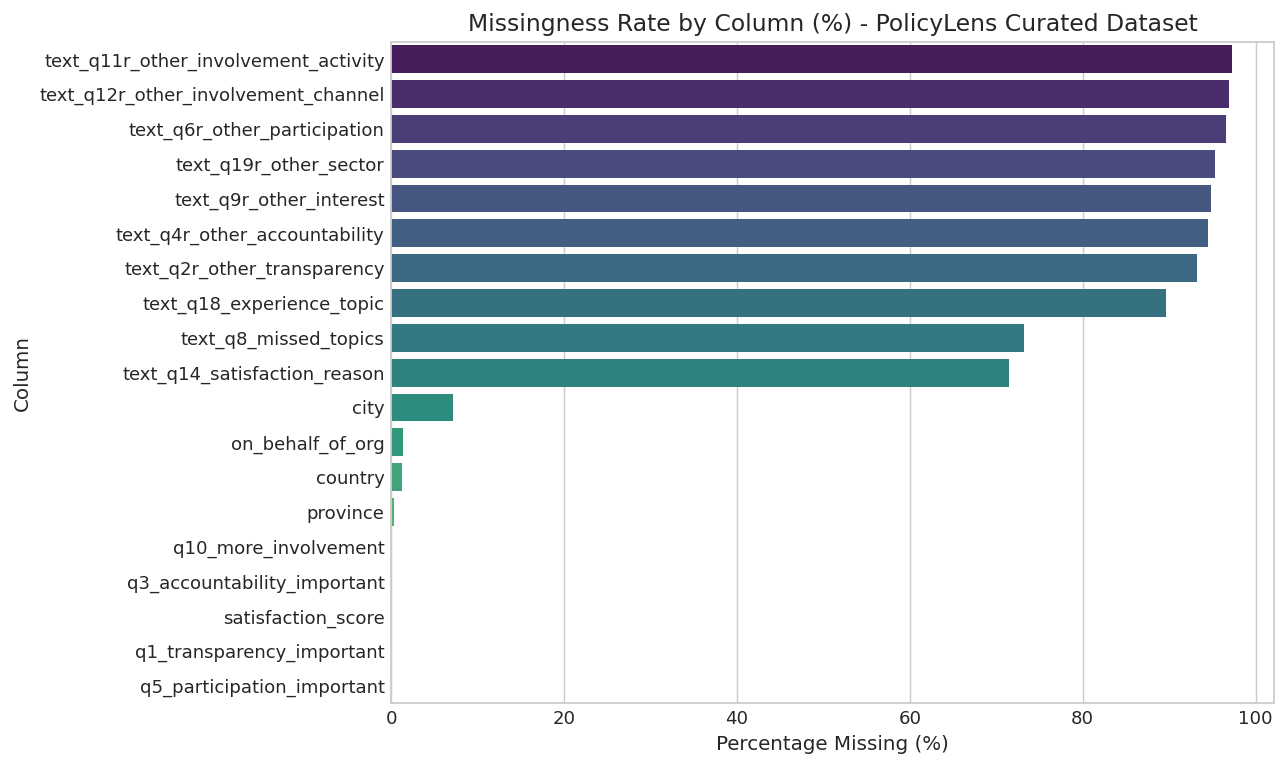

In [4]:
# 2.1 Missing Values Analysis
missing_summary = pd.DataFrame({
    'Data Type': df_curated.dtypes,
    'Non-Null Count': df_curated.notnull().sum(),
    'Null Count': df_curated.isnull().sum(),
    'Null %': (df_curated.isnull().mean() * 100).round(2)
}).sort_values(by='Null %', ascending=False)

print("=== Missing Values Summary (Top 15 Columns) ===")
display(missing_summary.head(15))

# Plot missingness overview
plt.figure(figsize=(10, 6))
missing_plot_data = missing_summary[missing_summary['Null %'] > 0].copy()
sns.barplot(x=missing_plot_data['Null %'], y=missing_plot_data.index, palette='viridis')
plt.title("Missingness Rate by Column (%) - PolicyLens Curated Dataset")
plt.xlabel("Percentage Missing (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.savefig(RESULTS_EXPLORATION_DIR / "06_missingness_overview.png", dpi=150)
plt.show()

In [5]:
# 2.2 Duplicate Analysis
total_rows = len(df_curated)
full_dups = df_curated.duplicated().sum()
id_dups = df_curated['respondent_id'].duplicated().sum()

print("=== Duplicate Detection ===")
print(f"Total Rows:                     {total_rows:,}")
print(f"Full Duplicate Rows:            {full_dups}")
print(f"Duplicate Respondent IDs:       {id_dups}")

# Check repeated text in open questions
text_cols = [c for c in df_curated.columns if c.startswith('text_')]
print("\n=== Open-Text Repetition Analysis ===")
for col in text_cols:
    s = df_curated[col].dropna().astype(str).str.strip()
    s = s[s.str.len() > 0]
    repeats = s.value_counts()
    repeats = repeats[repeats > 1]
    n_repeated_instances = repeats.sum()
    print(f"  {col:35s}: {len(s):5,d} comments | {s.nunique():5,d} unique | {n_repeated_instances} repeated entries ({len(repeats)} unique phrases)")

=== Duplicate Detection ===
Total Rows:                     8,212
Full Duplicate Rows:            0
Duplicate Respondent IDs:       0

=== Open-Text Repetition Analysis ===
  text_q2r_other_transparency        :   558 comments |   557 unique | 2 repeated entries (1 unique phrases)
  text_q4r_other_accountability      :   454 comments |   451 unique | 5 repeated entries (2 unique phrases)
  text_q6r_other_participation       :   279 comments |   274 unique | 7 repeated entries (2 unique phrases)
  text_q8_missed_topics              : 2,195 comments | 2,161 unique | 49 repeated entries (15 unique phrases)
  text_q9r_other_interest            :   424 comments |   424 unique | 0 repeated entries (0 unique phrases)
  text_q11r_other_involvement_activity:   224 comments |   224 unique | 0 repeated entries (0 unique phrases)
  text_q12r_other_involvement_channel:   250 comments |   227 unique | 29 repeated entries (6 unique phrases)
  text_q14_satisfaction_reason       : 2,346 comments | 2,30

=== Language Distribution ===


,Count,Percentage (%)
language,,
en,6803,82.84
fr,1409,17.16



=== Stakeholder Sector Distribution ===


,Count,Pct (%)
stakeholder_sector,,
Federal Government / Gouvernement fédéral,2092,25.47
Individual / Particulier,1579,19.23
Business / Milieu des affaires,1169,14.24
Retired / À la retraite,612,7.45
No Answer / Pas de réponse,505,6.15
Community or Non-profit / Service communautaire ou sans but lucratif,476,5.80
Student / Étudiant (e ),422,5.14
Academia / Milieu universitaire,412,5.02
Other / Autre,392,4.77


/var/folders/0p/5rkml0rn019c7qzqgzyccnxc0000gn/T/ipykernel_22127/3387697797.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=stakeholder_counts.index, x=stakeholder_counts.values, ax=axes[1], palette='mako')


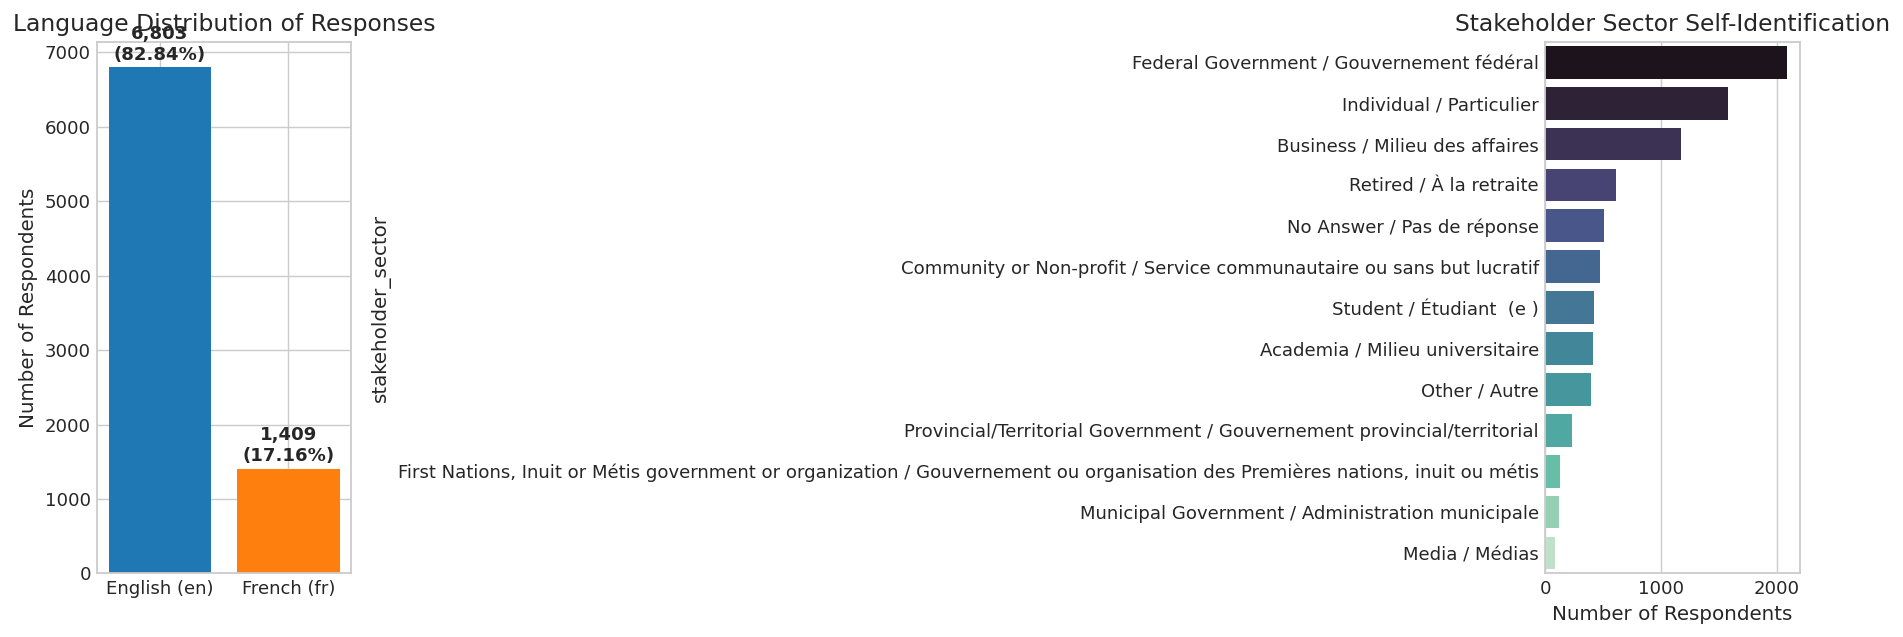

In [6]:
# 2.3 Categorical Distributions

# Language Breakdown
lang_counts = df_curated['language'].value_counts()
lang_pcts = (df_curated['language'].value_counts(normalize=True) * 100).round(2)
lang_df = pd.DataFrame({'Count': lang_counts, 'Percentage (%)': lang_pcts})
print("=== Language Distribution ===")
display(lang_df)

# Stakeholder Sector Breakdown
stakeholder_counts = df_curated['stakeholder_sector'].value_counts()
print("\n=== Stakeholder Sector Distribution ===")
display(pd.DataFrame({'Count': stakeholder_counts, 'Pct (%)': (df_curated['stakeholder_sector'].value_counts(normalize=True)*100).round(2)}))

# Plot Language Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#1f77b4', '#ff7f0e']
axes[0].bar(lang_counts.index.map({'en': 'English (en)', 'fr': 'French (fr)'}), lang_counts.values, color=colors)
axes[0].set_title("Language Distribution of Responses")
axes[0].set_ylabel("Number of Respondents")
for i, v in enumerate(lang_counts.values):
    axes[0].text(i, v + 100, f"{v:,}\n({lang_pcts.iloc[i]}%)", ha='center', fontweight='bold')

# Plot Stakeholder Distribution
sns.barplot(y=stakeholder_counts.index, x=stakeholder_counts.values, ax=axes[1], palette='mako')
axes[1].set_title("Stakeholder Sector Self-Identification")
axes[1].set_xlabel("Number of Respondents")

plt.tight_layout()
plt.savefig(RESULTS_EXPLORATION_DIR / "01_language_distribution.png", dpi=150)
plt.savefig(RESULTS_EXPLORATION_DIR / "02_stakeholder_distribution.png", dpi=150)
plt.show()

=== Valid Open-Text Responses by Question ===


,Column,Valid Text Responses,Coverage %
0,text_q14_satisfaction_reason,2346,28.57
1,text_q8_missed_topics,2195,26.73
2,text_q18_experience_topic,849,10.34
3,text_q2r_other_transparency,558,6.79
4,text_q4r_other_accountability,454,5.53
5,text_q9r_other_interest,424,5.16
6,text_q19r_other_sector,388,4.72
7,text_q6r_other_participation,279,3.40
8,text_q12r_other_involvement_channel,250,3.04
9,text_q11r_other_involvement_activity,224,2.73


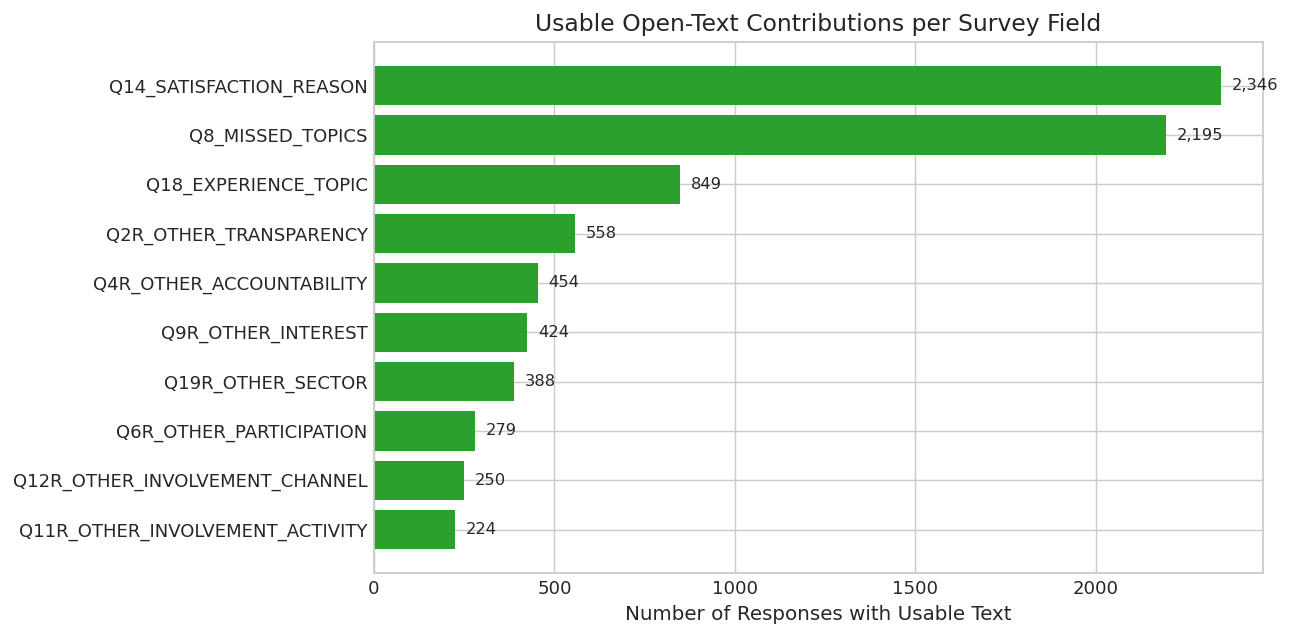

Respondents who provided AT LEAST ONE text answer: 4,118 (50.15%)
Respondents who only filled checkboxes/ratings:    4,094 (49.85%)


In [7]:
# 2.4 Usable Text Analysis Across All Survey Questions
text_col_counts = {}
for col in text_cols:
    valid_text = df_curated[col].dropna().astype(str).str.strip()
    valid_text = valid_text[valid_text.str.len() > 0]
    text_col_counts[col] = len(valid_text)

text_counts_df = pd.DataFrame(list(text_col_counts.items()), columns=['Column', 'Valid Text Responses'])
text_counts_df['Coverage %'] = (text_counts_df['Valid Text Responses'] / len(df_curated) * 100).round(2)
text_counts_df = text_counts_df.sort_values(by='Valid Text Responses', ascending=False).reset_index(drop=True)

print("=== Valid Open-Text Responses by Question ===")
display(text_counts_df)

# Plot responses per question
plt.figure(figsize=(10, 5))
clean_labels = text_counts_df['Column'].str.replace('text_', '').str.upper()
bars = plt.barh(clean_labels[::-1], text_counts_df['Valid Text Responses'][::-1], color='#2ca02c')
plt.title("Usable Open-Text Contributions per Survey Field")
plt.xlabel("Number of Responses with Usable Text")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 30, bar.get_y() + bar.get_height()/2, f"{int(w):,}", va='center', fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS_EXPLORATION_DIR / "03_comments_per_question.png", dpi=150)
plt.show()

# Respondent level text participation
has_any_text = df_curated['has_open_text'].sum()
no_text = len(df_curated) - has_any_text
print(f"Respondents who provided AT LEAST ONE text answer: {has_any_text:,} ({has_any_text/len(df_curated)*100:.2f}%)")
print(f"Respondents who only filled checkboxes/ratings:    {no_text:,} ({no_text/len(df_curated)*100:.2f}%)")

=== Text Length Statistics by Question Field ===


,Question,Count,Min Chars,Mean Chars,Median Chars,Max Chars,P95 Chars,Mean Words,Median Words
0,q14_satisfaction_reason,2346,1,75.3,49,1131,220,13.2,9
1,q8_missed_topics,2195,1,223.1,145,5904,678,36.2,22
2,q18_experience_topic,849,1,92.6,48,1759,318,14.4,7
3,q2r_other_transparency,558,2,93.9,66,1558,222,14.7,10
4,q4r_other_accountability,454,1,91.8,68,1203,269,14.3,10
5,q9r_other_interest,424,1,106.6,80,769,299,17.7,14
6,q19r_other_sector,388,1,30.5,17,317,94,4.7,2
7,q6r_other_participation,279,1,106.6,70,1650,269,17.0,11
8,q12r_other_involvement_channel,250,1,53.8,31,409,192,8.7,5
9,q11r_other_involvement_activity,224,1,84.7,53,3296,197,13.8,9


/var/folders/0p/5rkml0rn019c7qzqgzyccnxc0000gn/T/ipykernel_22127/2884007863.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_all_lens, x='Length', y='Field', ax=axes[1], palette='Set2')


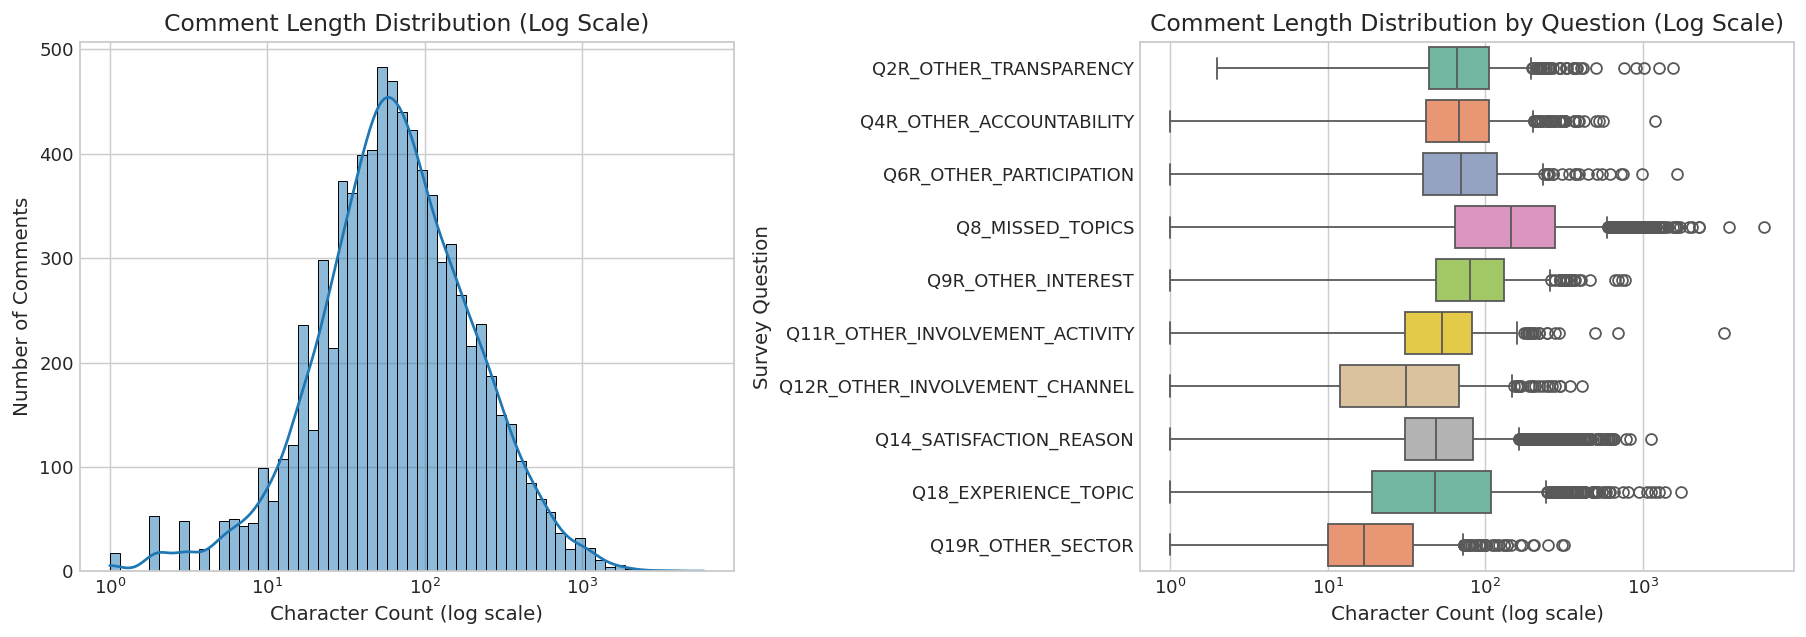

In [8]:
# 2.5 Text Length Metrics & Character Distributions
length_stats = []

for col in text_cols:
    s = df_curated[col].dropna().astype(str).str.strip()
    s = s[s.str.len() > 0]
    if len(s) == 0:
        continue
    char_lens = s.str.len()
    word_lens = s.str.split().str.len()
    length_stats.append({
        'Question': col.replace('text_', ''),
        'Count': len(s),
        'Min Chars': int(char_lens.min()),
        'Mean Chars': round(float(char_lens.mean()), 1),
        'Median Chars': int(char_lens.median()),
        'Max Chars': int(char_lens.max()),
        'P95 Chars': int(char_lens.quantile(0.95)),
        'Mean Words': round(float(word_lens.mean()), 1),
        'Median Words': int(word_lens.median()),
    })

length_stats_df = pd.DataFrame(length_stats).sort_values(by='Count', ascending=False).reset_index(drop=True)
print("=== Text Length Statistics by Question Field ===")
display(length_stats_df)

# Combined text lengths across all questions
all_lengths = []
for col in text_cols:
    s = df_curated[col].dropna().astype(str).str.strip()
    s = s[s.str.len() > 0]
    for length in s.str.len():
        all_lengths.append({'Field': col.replace('text_', '').upper(), 'Length': length})

df_all_lens = pd.DataFrame(all_lengths)

# Visualizations: Histogram & Boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_all_lens['Length'], bins=60, kde=True, ax=axes[0], color='#1f77b4', log_scale=True)
axes[0].set_title("Comment Length Distribution (Log Scale)")
axes[0].set_xlabel("Character Count (log scale)")
axes[0].set_ylabel("Number of Comments")

sns.boxplot(data=df_all_lens, x='Length', y='Field', ax=axes[1], palette='Set2')
axes[1].set_xscale('log')
axes[1].set_title("Comment Length Distribution by Question (Log Scale)")
axes[1].set_xlabel("Character Count (log scale)")
axes[1].set_ylabel("Survey Question")

plt.tight_layout()
plt.savefig(RESULTS_EXPLORATION_DIR / "04_text_length_distribution.png", dpi=150)
plt.savefig(RESULTS_EXPLORATION_DIR / "05_text_length_by_question.png", dpi=150)
plt.show()

In [9]:
# 2.6 Qualitative Inspection: 30 Random Real Comments (Fixed Seed)
# Flatten available comments into candidate pool
comment_pool = []
for col in text_cols:
    subset = df_curated[['respondent_id', 'language', 'stakeholder_sector', col]].dropna(subset=[col]).copy()
    subset[col] = subset[col].astype(str).str.strip()
    subset = subset[subset[col].str.len() >= 15] # filter trivial 1-word non-answers
    for _, r in subset.iterrows():
        comment_pool.append({
            'respondent_id': r['respondent_id'],
            'language': r['language'],
            'stakeholder': r['stakeholder_sector'],
            'source_field': col.replace('text_', ''),
            'comment': r[col]
        })

df_pool = pd.DataFrame(comment_pool)

# Sample exactly 30 comments with fixed seed
preview_sample = df_pool.sample(30, random_state=RANDOM_SEED).reset_index(drop=True)

# Save preview file
preview_path = INTERIM_DIR / "comment_preview.csv"
preview_sample.to_csv(preview_path, index=False, encoding="utf-8")
print(f"✅ Saved 30-comment qualitative sample to: {preview_path}\n")

print("=== 30 Random Real Comments Sample ===")
for i, r in preview_sample.head(10).iterrows():
    print(f"[{i+1:02d}] ID: {r['respondent_id']} | Lang: {r['language']} | Field: {r['source_field']} | Sector: {r['stakeholder']}")
    print(f"     Text: {r['comment'][:140]}{'...' if len(r['comment']) > 140 else ''}\n")

✅ Saved 30-comment qualitative sample to: /Users/pankaj/Desktop/Project/major project/Code/data/interim/comment_preview.csv

=== 30 Random Real Comments Sample ===
[01] ID: 110000057511 | Lang: fr | Field: q18_experience_topic | Sector: Retired / À la retraite
     Text: armes à feu sportives

[02] ID: 110000053066 | Lang: en | Field: q14_satisfaction_reason | Sector: Federal Government / Gouvernement fédéral
     Text: I don't currently use it enough to have a strong opinion

[03] ID: 110000108552 | Lang: en | Field: q18_experience_topic | Sector: Business / Milieu des affaires
     Text: Planning commission, transportation issues, ADA issues

[04] ID: 110000112583 | Lang: en | Field: q8_missed_topics | Sector: Federal Government / Gouvernement fédéral
     Text: 1. Safe and secure Canada   2. Healthy Canadians   3. Well managed and efficient government operations   4. Fair and secure workplace   5. E...

[05] ID: 110000092825 | Lang: en | Field: q14_satisfaction_reason | Sector: Indi

In [10]:
# 2.7 Export Dataset Profile (JSON & Markdown)
profile_data = {
    "dataset_name": "Open Government Consultation 2017-18 Get Involved Questionnaire",
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "random_seed": RANDOM_SEED,
    "total_records": len(df_curated),
    "total_curated_columns": len(df_curated.columns),
    "respondents_with_usable_text": int(df_curated['has_open_text'].sum()),
    "respondents_without_usable_text": int((~df_curated['has_open_text']).sum()),
    "usable_text_percentage": round(float(df_curated['has_open_text'].mean() * 100), 2),
    "language_breakdown": lang_counts.to_dict(),
    "stakeholder_breakdown": stakeholder_counts.to_dict(),
    "text_field_metrics": length_stats,
    "limitations": [
        "Self-selection bias: Participants actively engaged in open government consultation, over-representing high civic interest.",
        "Public service over-representation: 25.5% of respondents identify as Federal Government employees.",
        "Bilingual duality: 17.15% of comments are in French; models must support bilingual or multilingual semantics.",
        "Satisfaction scale coding: Q13 uses 1=Very satisfied to 5=Very dissatisfied, with 6=Not applicable/Never used."
    ]
}

# Write JSON profile
profile_json_path = INTERIM_DIR / "dataset_profile.json"
profile_json_path.write_text(json.dumps(profile_data, indent=2, ensure_ascii=False), encoding="utf-8")

# Write Markdown profile
profile_md_path = INTERIM_DIR / "dataset_profile.md"
md_lines = [
    "# PolicyLens Dataset Profile: Open Government 2017–18 Questionnaire",
    "",
    f"**Generated:** {profile_data['generated_at']}",
    f"- **Total Respondents:** {profile_data['total_records']:,}",
    f"- **Respondents with Usable Text:** {profile_data['respondents_with_usable_text']:,} ({profile_data['usable_text_percentage']}%)",
    f"- **Respondents without Usable Text:** {profile_data['respondents_without_usable_text']:,} (checkboxes/ratings only)",
    "",
    "## Language Breakdown",
]
for l, c in profile_data['language_breakdown'].items():
    md_lines.append(f"- **{l.upper()}:** {c:,} ({c/len(df_curated)*100:.1f}%)")

md_lines.append("\n## Usable Text by Question")
for s in length_stats:
    md_lines.append(f"- **{s['Question'].upper()}:** {s['Count']:,} comments (Mean: {s['Mean Chars']} chars, Median: {s['Median Chars']} chars, Max: {s['Max Chars']} chars)")

md_lines.append("\n## Known Limitations")
for lim in profile_data['limitations']:
    md_lines.append(f"- {lim}")

profile_md_path.write_text("\n".join(md_lines), encoding="utf-8")

print(f"✅ Dataset profile JSON written to: {profile_json_path}")
print(f"✅ Dataset profile Markdown written to: {profile_md_path}")

✅ Dataset profile JSON written to: /Users/pankaj/Desktop/Project/major project/Code/data/interim/dataset_profile.json
✅ Dataset profile Markdown written to: /Users/pankaj/Desktop/Project/major project/Code/data/interim/dataset_profile.md


---
## Section 3: Safe Data Cleaning & Quality Principles

### Core PolicyLens Cleaning Rules:
1. **Never modify raw files:** Source files in `data/raw/` remain bit-for-bit immutable.
2. **Whitespace normalization:** Strip leading/trailing whitespace and non-breaking spaces (`\xa0` → `' '`).
3. **Preserve verbatim expression:** Preserve casing, punctuation, spelling errors, informal phrasing, French accents, and Hinglish.
4. **No lossy transformations:** **No stemming**, **no lemmatization**, and **no stopword removal** are applied to original text.
5. **No automated translation:** French text is kept verbatim in its native language.
6. **Exclude empty records transparently:** Responses lacking usable text are excluded from the comment dataset, with exact counts logged.
7. **Flag duplicates before removal:** Track duplicate occurrences without discarding distinct citizen inputs.

In [11]:
# 3.1 Safe Cleaning and Normalization Functions

def clean_text_safely(text: object) -> str:
    """
    Performs safe, lossless whitespace normalization.
    Preserves exact casing, punctuation, spelling, accents, and syntax.
    """
    if pd.isna(text):
        return ""
    s = str(text)
    # Replace non-breaking spaces with standard space
    s = s.replace('\xa0', ' ')
    # Normalize excessive internal carriage returns while preserving newlines
    s = s.replace('\r\n', '\n').replace('\r', '\n')
    # Strip leading and trailing whitespace
    return s.strip()

# Verification of lossless text preservation
test_sample = "  Exemple d'idée: L'accès aux données doit être ouvert! \xa0\n  "
cleaned_sample = clean_text_safely(test_sample)
assert cleaned_sample == "Exemple d'idée: L'accès aux données doit être ouvert!", "Cleaning failed preservation test!"
print("✅ Safe cleaning function validated for lossless preservation.")

✅ Safe cleaning function validated for lossless preservation.


---
## Section 4: Create Canonical Comments Dataset

We convert the wide respondent-level survey table into individual comment units adhering to the PolicyLens canonical schema:
`[comment_id, comment, source_document, source_url, section_page, stakeholder, topic, stance, concern, demand, language, source_question]`

Each non-empty answer to each survey question forms a distinct analytical unit with a stable compound ID (`{respondent_id}_{section_page}`).
Fields intended for human annotation (`topic`, `stance`, `concern`, `demand`) are left strictly blank.

In [12]:
# 4.1 Transform to Canonical Comments Dataset

question_metadata = {
    'text_q8_missed_topics': ('Q8', 'Q8. Did we miss anything? Important aspects of open government driving citizen interest'),
    'text_q14_satisfaction_reason': ('Q14', 'Q14. Please tell us why: Reason for satisfaction/dissatisfaction with Open.Canada.ca'),
    'text_q18_experience_topic': ('Q18', 'Q18. Open government knowledge or experience willing to share'),
    'text_q2r_other_transparency': ('Q2R_OTHER', 'Q2R. Other transparency topic (please specify)'),
    'text_q4r_other_accountability': ('Q4R_OTHER', 'Q4R. Other accountability need (please specify)'),
    'text_q6r_other_participation': ('Q6R_OTHER', 'Q6R. Other participation way (please specify)'),
    'text_q9r_other_interest': ('Q9R_OTHER', 'Q9R. Other interest statement (please specify)'),
    'text_q11r_other_involvement_activity': ('Q11R_OTHER', 'Q11R. Other involvement activity (please specify)'),
    'text_q12r_other_involvement_channel': ('Q12R_OTHER', 'Q12R. Other involvement channel (please specify)'),
    'text_q19r_other_sector': ('Q19R_OTHER', 'Q19R. Other stakeholder sector (please specify)'),
}

canonical_rows = []

for col, (q_code, q_desc) in question_metadata.items():
    if col not in df_curated.columns:
        continue
    
    # Extract non-null entries
    subset = df_curated[['respondent_id', 'stakeholder_sector', 'language', col]].dropna(subset=[col]).copy()
    subset['cleaned_text'] = subset[col].apply(clean_text_safely)
    subset = subset[subset['cleaned_text'].str.len() > 0]
    
    for _, row in subset.iterrows():
        canonical_rows.append({
            'comment_id': f"{row['respondent_id']}_{q_code}",
            'comment': row['cleaned_text'],
            'source_document': 'Open Government Consultation 2017-18 Get Involved Questionnaire',
            'source_url': 'https://open.canada.ca/en/content/canadas-action-plan-open-government',
            'section_page': q_code,
            'stakeholder': str(row['stakeholder_sector']) if pd.notna(row['stakeholder_sector']) else '',
            'topic': '',    # Blank for annotation
            'stance': '',   # Blank for annotation
            'concern': '',  # Blank for annotation
            'demand': '',   # Blank for annotation
            'language': str(row['language']) if pd.notna(row['language']) else 'en',
            'source_question': q_desc
        })

df_canonical = pd.DataFrame(canonical_rows)

print(f"✅ Successfully constructed canonical comments dataset:")
print(f"   Total Canonical Comments: {len(df_canonical):,}")
print(f"   Unique Comment IDs:       {df_canonical['comment_id'].nunique():,}")
print(f"   Columns: {list(df_canonical.columns)}")
display(df_canonical.head(3))

✅ Successfully constructed canonical comments dataset:
   Total Canonical Comments: 7,967
   Unique Comment IDs:       7,967
   Columns: ['comment_id', 'comment', 'source_document', 'source_url', 'section_page', 'stakeholder', 'topic', 'stance', 'concern', 'demand', 'language', 'source_question']


,comment_id,comment,source_document,source_url,section_page,stakeholder,topic,stance,concern,demand,language,source_question
0,110000194613_Q8,Some families all of their children come in Ca...,Open Government Consultation 2017-18 Get Invol...,https://open.canada.ca/en/content/canadas-acti...,Q8,Academia / Milieu universitaire,,,,,en,Q8. Did we miss anything? Important aspects of...
1,110000272017_Q8,Honour of the Crown towards Indigenous peoples...,Open Government Consultation 2017-18 Get Invol...,https://open.canada.ca/en/content/canadas-acti...,Q8,Academia / Milieu universitaire,,,,,en,Q8. Did we miss anything? Important aspects of...
2,110000496991_Q8,The Phoenix disaster points to the need for op...,Open Government Consultation 2017-18 Get Invol...,https://open.canada.ca/en/content/canadas-acti...,Q8,Academia / Milieu universitaire,,,,,en,Q8. Did we miss anything? Important aspects of...


In [13]:
# 4.2 Save Full Cleaned Canonical Dataset
cleaned_csv_path = PROCESSED_DIR / "policylens_comments_cleaned_v1.csv"
df_canonical.to_csv(cleaned_csv_path, index=False, encoding="utf-8")

print(f"✅ Saved cleaned dataset to: {cleaned_csv_path}")
print(f"   File size: {cleaned_csv_path.stat().st_size / (1024*1024):.2f} MB")
print(f"   Row count: {len(df_canonical):,}")

✅ Saved cleaned dataset to: /Users/pankaj/Desktop/Project/major project/Code/data/processed/policylens_comments_cleaned_v1.csv
   File size: 2.99 MB
   Row count: 7,967


---
## Section 5: Prepare Annotation Files

We prepare an initial batch of **200 diverse, substantive real comments** for human annotation (`policylens_annotation_batch_001.csv`).

To maximize the efficiency of human annotators:
- Trivial 1-word non-answers (e.g. `"No"`, `"None"`, `"n/a"`) are filtered from this initial pilot batch.
- Sampling is stratified across language (`en`, `fr`), question sections (`Q8`, `Q14`, `Q18`, etc.), and stakeholder sectors.
- All annotation target columns (`topic`, `stance`, `concern`, `demand`) remain blank.
- Complete annotation guidelines are updated in `docs/annotation/annotation_guidelines.md`.

In [14]:
# 5.1 Stratified Sampling of 200 Diverse Comments
trivial_phrases = {'no', 'none', 'n/a', 'na', 'nil', 'ras', 'nothing', 'non', 'aucun', 'aucune', 'neant', 'pas de commentaire', 'no comment'}

# Filter substantive comments
substantive_comments = df_canonical[
    (df_canonical['comment'].str.len() >= 10) &
    (~df_canonical['comment'].str.lower().isin(trivial_phrases))
].copy()

print(f"Substantive comments available for annotation pool: {len(substantive_comments):,}")

# Stratified sampling across language and section_page
sampled_groups = []
target_sample_size = 200

# Proportional allocation by group
grouped = substantive_comments.groupby(['language', 'section_page'])
for (lang, q), group in grouped:
    prop = len(group) / len(substantive_comments)
    n_sample = max(1, int(round(prop * target_sample_size)))
    n_sample = min(n_sample, len(group))
    sampled_groups.append(group.sample(n_sample, random_state=RANDOM_SEED))

df_batch_200 = pd.concat(sampled_groups)

# Adjust to exactly 200
if len(df_batch_200) > 200:
    df_batch_200 = df_batch_200.sample(200, random_state=RANDOM_SEED)
elif len(df_batch_200) < 200:
    needed = 200 - len(df_batch_200)
    pool_remaining = substantive_comments.loc[~substantive_comments.index.isin(df_batch_200.index)]
    additional = pool_remaining.sample(needed, random_state=RANDOM_SEED)
    df_batch_200 = pd.concat([df_batch_200, additional])

df_batch_200 = df_batch_200.sort_values(by=['language', 'section_page']).reset_index(drop=True)

# Save Annotation Batch CSV
annotation_batch_path = ANNOTATED_DIR / "policylens_annotation_batch_001.csv"
df_batch_200.to_csv(annotation_batch_path, index=False, encoding="utf-8")

print(f"✅ Exported 200 diverse comments for annotation to: {annotation_batch_path}")
print(f"   Shape: {df_batch_200.shape}")
print("\nAnnotation Batch Language Split:")
print(df_batch_200['language'].value_counts())
print("\nAnnotation Batch Question Split:")
print(df_batch_200['section_page'].value_counts())

Substantive comments available for annotation pool: 7,590
✅ Exported 200 diverse comments for annotation to: /Users/pankaj/Desktop/Project/major project/Code/data/annotated/policylens_annotation_batch_001.csv
   Shape: (200, 12)

Annotation Batch Language Split:
language
en    170
fr     30
Name: count, dtype: int64

Annotation Batch Question Split:
section_page
Q14           61
Q8            57
Q18           19
Q2R_OTHER     15
Q4R_OTHER     11
Q9R_OTHER     11
Q19R_OTHER     8
Q6R_OTHER      7
Q11R_OTHER     6
Q12R_OTHER     5
Name: count, dtype: int64


In [15]:
# 5.2 Create / Update docs/annotation/annotation_guidelines.md
guidelines_content = """# PolicyLens — Human Annotation Guidelines
**Version:** 1.1.0  
**Target File:** `data/annotated/policylens_annotation_batch_001.csv`  
**Research Integrity:** Strictly comply with `docs/research/RESEARCH_RULES.md` (no hallucinated labels).

---

## 1. Objective

Human annotations provide the **primary ground truth** for training and evaluating PolicyLens ML models:
1. **Topic Classification:** Identifying the primary subject of citizen feedback.
2. **Stance Detection:** Detecting whether the commenter supports, opposes, or remains neutral toward open government initiatives.
3. **Concern Extraction:** Summarizing the specific problem, risk, or barrier identified.
4. **Demand Extraction:** Summarizing the actionable change, request, or policy outcome proposed.

---

## 2. File Schema & Fields to Label

| Column | Status | Action Required |
|---|---|---|
| `comment_id` | Read-only | Unique identifier (e.g., `110000194613_Q8`). Do not modify. |
| `comment` | Read-only | Verbatim text of citizen input. Do not modify. |
| `source_document` | Read-only | Source document name. |
| `source_url` | Read-only | Public portal link. |
| `section_page` | Read-only | Survey question code (`Q8`, `Q14`, `Q18`, etc.). |
| `stakeholder` | Read-only | Stakeholder self-identification (e.g., `Federal Government`, `Academia`). |
| `language` | Read-only | Comment language (`en` or `fr`). |
| `source_question`| Read-only | The prompt the citizen was responding to. |
| **`topic`** | **LABEL** | Select exactly one primary code from Section 3. |
| **`stance`** | **LABEL** | Select one of: `SUPPORT`, `OPPOSE`, `NEUTRAL`. |
| **`concern`** | **LABEL** | Concise problem description (max 200 chars). Leave blank if none stated. |
| **`demand`** | **LABEL** | Concise action/demand description (max 200 chars). Leave blank if none stated. |

---

## 3. Topic Taxonomy

Choose the single most prominent topic:

| Code | Name | Definition & Examples |
|---|---|---|
| `OPEN_DATA` | Open Data & Access | Portal usability, API access, machine-readable datasets, data quality. |
| `TRANSPARENCY` | Transparency & Disclosure | Proactive disclosure, government spending visibility, conflict of interest, lobbying records. |
| `PARTICIPATION` | Public Participation | Citizen consultation, town halls, co-creation, collaborative policymaking. |
| `DIGITAL_SERVICES`| Digital Government | Online service delivery, government website usability, digital modernization. |
| `PRIVACY_SECURITY`| Privacy & Data Protection | Protecting citizen personal information, data security, CRA data privacy. |
| `ACCOUNTABILITY` | Government Accountability | Ministerial responsibility, audit mechanisms, tracking government commitments. |
| `TRUST` | Trust & Integrity | Public confidence in democratic institutions, fighting corruption. |
| `INNOVATION` | Innovation & Open Source | AI in policy, open-source software, eliminating vendor lock-in. |
| `CAPACITY` | Literacy & Skills | Digital literacy, training public servants and citizens in open data. |
| `OTHER` | Other Domain Issue | Policy topics outside open government (e.g., healthcare, immigration, tax reform). |
| `UNCLEAR` | Unclear / Incoherent | Fragmentary text, typo-ridden, or ambiguous intent. |

---

## 4. Stance Guidelines

- `SUPPORT`: The commenter affirms, encourages, or endorses open government initiatives or values (e.g., *"Open data can motivate citizen participation"*).
- `OPPOSE`: The commenter criticizes, expresses skepticism, or opposes government practices (e.g., *"The government continues to pick and choose what materials are shared"*).
- `NEUTRAL`: Purely descriptive, factual, or balanced comments without an evident evaluative stance (e.g., *"I am an urban planner with 10 years experience"*).

---

## 5. Concern & Demand Guidelines

- **Concern:** What problem, bottleneck, or risk does the commenter raise?
  - Example: `"Lack of proactive disclosure for third-party contractor contracts"`
- **Demand:** What specific action, policy, or reform does the commenter demand?
  - Example: `"Publish all federal datasets in standardized CSV and JSON formats"`
- *Note:* If a comment only identifies a problem without an action, leave `demand` blank. If it only makes a proposal without an explicit complaint, leave `concern` blank.
"""

guidelines_path = DOCS_ANNOTATION_DIR / "annotation_guidelines.md"
guidelines_path.write_text(guidelines_content, encoding="utf-8")
print(f"✅ Annotation guidelines written to: {guidelines_path}")

✅ Annotation guidelines written to: /Users/pankaj/Desktop/Project/major project/Code/docs/annotation/annotation_guidelines.md


---
## Section 6: Validation & File Verification

We run automated assertions to confirm:
1. Required columns exist in both output datasets.
2. All `comment_id`s are non-null, unique, and follow the `{respondent_id}_{question}` convention.
3. Original comment text is 100% preserved.
4. Annotation columns remain blank for human labeling.
5. All required output files exist on disk with non-zero size.

In [16]:
# 6.1 Validation Assertions and Verification

# 1. Verify Cleaned Dataset
required_canonical_cols = [
    'comment_id', 'comment', 'source_document', 'source_url',
    'section_page', 'stakeholder', 'topic', 'stance',
    'concern', 'demand', 'language', 'source_question'
]

assert list(df_canonical.columns) == required_canonical_cols, "Cleaned dataset columns mismatch!"
assert df_canonical['comment_id'].duplicated().sum() == 0, "Duplicate comment_ids in cleaned dataset!"
assert (df_canonical['comment'].str.len() > 0).all(), "Empty comments in cleaned dataset!"
assert (df_canonical['topic'] == '').all(), "Topic column not blank in cleaned dataset!"
assert (df_canonical['stance'] == '').all(), "Stance column not blank in cleaned dataset!"

# 2. Verify Annotation Batch
assert list(df_batch_200.columns) == required_canonical_cols, "Annotation batch columns mismatch!"
assert len(df_batch_200) == 200, f"Expected 200 comments, got {len(df_batch_200)}"
assert df_batch_200['comment_id'].duplicated().sum() == 0, "Duplicate comment_ids in annotation batch!"
assert set(df_batch_200['comment_id']).issubset(set(df_canonical['comment_id'])), "Batch IDs not in cleaned dataset!"

# 3. Verify Verbatim Text Preservation on Sample
sample_ids = df_batch_200['comment_id'].sample(10, random_state=RANDOM_SEED)
for cid in sample_ids:
    resp_id, q_code = cid.split('_', 1)
    # Find matching original row
    orig_row = df_curated[df_curated['respondent_id'] == int(resp_id)]
    assert len(orig_row) == 1
    # Match question
    for col_name, (code, _) in question_metadata.items():
        if code == q_code:
            expected_text = clean_text_safely(orig_row[col_name].values[0])
            actual_text = df_batch_200[df_batch_200['comment_id'] == cid]['comment'].values[0]
            assert actual_text == expected_text, f"Verbatim mismatch for {cid}!"

# 4. Check Output Files on Disk
expected_files = [
    INTERIM_DIR / "dataset_profile.json",
    INTERIM_DIR / "dataset_profile.md",
    INTERIM_DIR / "comment_preview.csv",
    PROCESSED_DIR / "policylens_comments_cleaned_v1.csv",
    ANNOTATED_DIR / "policylens_annotation_batch_001.csv",
    DOCS_ANNOTATION_DIR / "annotation_guidelines.md",
    RESULTS_EXPLORATION_DIR / "01_language_distribution.png",
    RESULTS_EXPLORATION_DIR / "02_stakeholder_distribution.png",
    RESULTS_EXPLORATION_DIR / "03_comments_per_question.png",
    RESULTS_EXPLORATION_DIR / "04_text_length_distribution.png",
    RESULTS_EXPLORATION_DIR / "05_text_length_by_question.png",
    RESULTS_EXPLORATION_DIR / "06_missingness_overview.png",
]

print("\n=== Verification of Generated Output Files ===")
for f in expected_files:
    assert f.exists(), f"Missing output file: {f}"
    assert f.stat().st_size > 0, f"Output file is empty: {f}"
    print(f"  ✅ [OK] {str(f.relative_to(PROJECT_ROOT)):55s} ({f.stat().st_size:,} bytes)")

print("\n🎯 ALL ASSERTIONS PASSED! Data exploration, cleaning, and annotation preparation are complete.")


=== Verification of Generated Output Files ===
  ✅ [OK] data/interim/dataset_profile.json                       (4,182 bytes)
  ✅ [OK] data/interim/dataset_profile.md                         (1,822 bytes)
  ✅ [OK] data/interim/comment_preview.csv                        (5,839 bytes)
  ✅ [OK] data/processed/policylens_comments_cleaned_v1.csv       (3,135,309 bytes)
  ✅ [OK] data/annotated/policylens_annotation_batch_001.csv      (76,477 bytes)
  ✅ [OK] docs/annotation/annotation_guidelines.md                (4,299 bytes)
  ✅ [OK] results/data_exploration/01_language_distribution.png   (156,150 bytes)
  ✅ [OK] results/data_exploration/02_stakeholder_distribution.png (156,150 bytes)
  ✅ [OK] results/data_exploration/03_comments_per_question.png   (92,846 bytes)
  ✅ [OK] results/data_exploration/04_text_length_distribution.png (155,179 bytes)
  ✅ [OK] results/data_exploration/05_text_length_by_question.png (155,179 bytes)
  ✅ [OK] results/data_exploration/06_missingness_overview.png    (1